#Imports

In [120]:
import os
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Reproducibility
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)


IMAGE_SIZE = 256
NUM_CLASSES = 4
BATCH_SIZE = 32

CLASS_NAMES = [
    "glioma_tumor",
    "meningioma_tumor",
    "no_tumor",
    "pituitary_tumor"
]

CLASS_TO_INDEX = {
    class_name: idx
    for idx, class_name in enumerate(CLASS_NAMES)
}

print("TensorFlow version:", tf.__version__)
print("Classes:", CLASS_NAMES)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)

TensorFlow version: 2.20.0
Classes: ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']
Image size: 256
Batch size: 16


#Download and Load data set

In [ ]:
import zipfile
ZIP_PATH = "/content/archive.zip"
EXTRACT_PATH = "/content/brain_tumor_dataset"

os.makedirs(EXTRACT_PATH, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_PATH)

print("Dataset extracted successfully!")

In [121]:
DATASET_ROOT = Path(
    "/content/brain_tumor_dataset"
)

TRAIN_DIR = DATASET_ROOT / "Training"
TEST_DIR = DATASET_ROOT / "Testing"

print("Training directory:", TRAIN_DIR)
print("Testing directory:", TEST_DIR)

print("\nTraining exists:", TRAIN_DIR.exists())
print("Testing exists:", TEST_DIR.exists())

Training directory: /content/brain_tumor_dataset/Training
Testing directory: /content/brain_tumor_dataset/Testing

Training exists: True
Testing exists: True


In [122]:
print("=" * 60)
print("TRAINING DATASET")
print("=" * 60)

for class_name in CLASS_NAMES:
    class_dir = TRAIN_DIR / class_name

    if class_dir.exists():
        count = len([
            f for f in class_dir.iterdir()
            if f.is_file()
        ])
        print(f"{class_name:20s}: {count}")

print("\n" + "=" * 60)
print("TESTING DATASET")
print("=" * 60)

for class_name in CLASS_NAMES:
    class_dir = TEST_DIR / class_name

    if class_dir.exists():
        count = len([
            f for f in class_dir.iterdir()
            if f.is_file()
        ])
        print(f"{class_name:20s}: {count}")

TRAINING DATASET
glioma_tumor        : 818
meningioma_tumor    : 814
no_tumor            : 335
pituitary_tumor     : 810

TESTING DATASET
glioma_tumor        : 84
meningioma_tumor    : 113
no_tumor            : 81
pituitary_tumor     : 36


In [123]:

VALID_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}


def collect_image_paths(root_dir, split_name):
    records = []

    for class_name in CLASS_NAMES:

        class_dir = root_dir / class_name

        if not class_dir.exists():
            print(f"WARNING: Missing directory: {class_dir}")
            continue

        for file_path in class_dir.iterdir():

            if not file_path.is_file():
                continue

            if file_path.suffix.lower() not in VALID_EXTENSIONS:
                continue

            records.append({
                "path": str(file_path),
                "label": class_name,
                "split": split_name
            })

    return pd.DataFrame(records)


train_df = collect_image_paths(
    TRAIN_DIR,
    "train_original"
)

test_df = collect_image_paths(
    TEST_DIR,
    "test_original"
)

print("Original training images:", len(train_df))
print("Original testing images :", len(test_df))

print("\nTraining distribution:")
print(train_df["label"].value_counts())

print("\nTesting distribution:")
print(test_df["label"].value_counts())

Original training images: 2777
Original testing images : 314

Training distribution:
label
glioma_tumor        818
meningioma_tumor    814
pituitary_tumor     810
no_tumor            335
Name: count, dtype: int64

Testing distribution:
label
meningioma_tumor    113
glioma_tumor         84
no_tumor             81
pituitary_tumor      36
Name: count, dtype: int64


#Data Set Cleaning

In [124]:


def check_image_readable(image_path):
    try:
        img = cv2.imread(image_path)

        if img is None:
            return False

        if img.size == 0:
            return False

        return True

    except Exception:
        return False


def find_corrupted_images(df):

    corrupted = []

    for path in tqdm(
        df["path"],
        desc="Checking images"
    ):
        if not check_image_readable(path):
            corrupted.append(path)

    return corrupted


train_corrupted = find_corrupted_images(train_df)
test_corrupted = find_corrupted_images(test_df)

print("\n" + "=" * 60)
print("CORRUPTED IMAGE REPORT")
print("=" * 60)

print("Training corrupted:", len(train_corrupted))
print("Testing corrupted :", len(test_corrupted))

Checking images:   0%|          | 0/2777 [00:00<?, ?it/s]

Checking images:   0%|          | 0/314 [00:00<?, ?it/s]


CORRUPTED IMAGE REPORT
Training corrupted: 0
Testing corrupted : 0


In [125]:
def get_file_hash(file_path, chunk_size=1024 * 1024):
    """
    Compute SHA-256 hash of the exact file bytes.
    This detects exact file duplicates only.
    """

    sha256 = hashlib.sha256()

    with open(file_path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            sha256.update(chunk)

    return sha256.hexdigest()


def add_file_hashes(df):

    df = df.copy()

    hashes = []

    for path in tqdm(
        df["path"],
        desc="Computing SHA-256 hashes"
    ):
        hashes.append(get_file_hash(path))

    df["file_hash"] = hashes

    return df


train_df = add_file_hashes(train_df)
test_df = add_file_hashes(test_df)

print("Hashing completed.")

Computing SHA-256 hashes:   0%|          | 0/2777 [00:00<?, ?it/s]

Computing SHA-256 hashes:   0%|          | 0/314 [00:00<?, ?it/s]

Hashing completed.


In [126]:
def analyze_duplicates(df, name):

    duplicate_mask = df["file_hash"].duplicated(
        keep=False
    )

    duplicates = df[duplicate_mask].copy()

    print("=" * 60)
    print(name)
    print("=" * 60)

    print("Total images:", len(df))
    print("Duplicate rows:", len(duplicates))
    print(
        "Unique files:",
        df["file_hash"].nunique()
    )

    if len(duplicates) > 0:

        print("\nDuplicate groups:")

        duplicate_groups = (
            duplicates
            .groupby("file_hash")
            .agg(
                count=("file_hash", "size"),
                paths=("path", list),
                labels=("label", list)
            )
        )

        display(duplicate_groups)

    return duplicates


train_duplicates = analyze_duplicates(
    train_df,
    "TRAINING DUPLICATES"
)

test_duplicates = analyze_duplicates(
    test_df,
    "TESTING DUPLICATES"
)

TRAINING DUPLICATES
Total images: 2777
Duplicate rows: 0
Unique files: 2777
TESTING DUPLICATES
Total images: 314
Duplicate rows: 0
Unique files: 314


In [127]:
train_hashes = set(train_df["file_hash"])
test_hashes = set(test_df["file_hash"])

cross_split_hashes = train_hashes.intersection(
    test_hashes
)

print("=" * 60)
print("CROSS-SPLIT EXACT DUPLICATES")
print("=" * 60)

print(
    "Exact files appearing in BOTH Training and Testing:",
    len(cross_split_hashes)
)

CROSS-SPLIT EXACT DUPLICATES
Exact files appearing in BOTH Training and Testing: 64


In [128]:


test_df_clean = test_df.drop_duplicates(
    subset="file_hash",
    keep="first"
).reset_index(drop=True)



train_df_clean = train_df[
    ~train_df["file_hash"].isin(
        set(test_df_clean["file_hash"])
    )
].copy()


train_df_clean = (
    train_df_clean
    .drop_duplicates(
        subset="file_hash",
        keep="first"
    )
    .reset_index(drop=True)
)


print("=" * 60)
print("AFTER EXACT DUPLICATE REMOVAL")
print("=" * 60)

print("Training before:", len(train_df))
print("Training after :", len(train_df_clean))

print("\nTesting before :", len(test_df))
print("Testing after  :", len(test_df_clean))

print("\nTraining duplicates after cleaning:",
      train_df_clean["file_hash"].duplicated().sum())

print("Testing duplicates after cleaning:",
      test_df_clean["file_hash"].duplicated().sum())

print(
    "\nCross-split duplicates after cleaning:",
    len(
        set(train_df_clean["file_hash"])
        &
        set(test_df_clean["file_hash"])
    )
)

AFTER EXACT DUPLICATE REMOVAL
Training before: 2777
Training after : 2713

Testing before : 314
Testing after  : 314

Training duplicates after cleaning: 0
Testing duplicates after cleaning: 0

Cross-split duplicates after cleaning: 0


# Train Test Splitting

In [129]:

print("=" * 60)
print("FINAL CLEAN DATASET")
print("=" * 60)

print("\nTRAINING")
print(train_df_clean["label"].value_counts().sort_index())

print("\nTESTING")
print(test_df_clean["label"].value_counts().sort_index())

print("\nTotal training images:", len(train_df_clean))
print("Total testing images :", len(test_df_clean))
print(
    "Total images:",
    len(train_df_clean) + len(test_df_clean)
)

FINAL CLEAN DATASET

TRAINING
label
glioma_tumor        818
meningioma_tumor    814
no_tumor            271
pituitary_tumor     810
Name: count, dtype: int64

TESTING
label
glioma_tumor         84
meningioma_tumor    113
no_tumor             81
pituitary_tumor      36
Name: count, dtype: int64

Total training images: 2713
Total testing images : 314
Total images: 3027


In [130]:


train_split_df, valid_split_df = train_test_split(
    train_df_clean,
    test_size=0.2,
    stratify=train_df_clean["label"],
    random_state=SEED
)

train_split_df = train_split_df.reset_index(drop=True)
valid_split_df = valid_split_df.reset_index(drop=True)

print("=" * 60)
print("FINAL SPLITS")
print("=" * 60)

print("Train      :", len(train_split_df))
print("Validation :", len(valid_split_df))
print("Test       :", len(test_df_clean))

print("\nTrain distribution:")
print(
    train_split_df["label"]
    .value_counts(normalize=False)
    .sort_index()
)

print("\nValidation distribution:")
print(
    valid_split_df["label"]
    .value_counts(normalize=False)
    .sort_index()
)

print("\nTest distribution:")
print(
    test_df_clean["label"]
    .value_counts(normalize=False)
    .sort_index()
)

FINAL SPLITS
Train      : 2170
Validation : 543
Test       : 314

Train distribution:
label
glioma_tumor        654
meningioma_tumor    651
no_tumor            217
pituitary_tumor     648
Name: count, dtype: int64

Validation distribution:
label
glioma_tumor        164
meningioma_tumor    163
no_tumor             54
pituitary_tumor     162
Name: count, dtype: int64

Test distribution:
label
glioma_tumor         84
meningioma_tumor    113
no_tumor             81
pituitary_tumor      36
Name: count, dtype: int64


                   Train  Validation    Test
label                                       
glioma_tumor      0.3014      0.3020  0.2675
meningioma_tumor  0.3000      0.3002  0.3599
no_tumor          0.1000      0.0994  0.2580
pituitary_tumor   0.2986      0.2983  0.1146


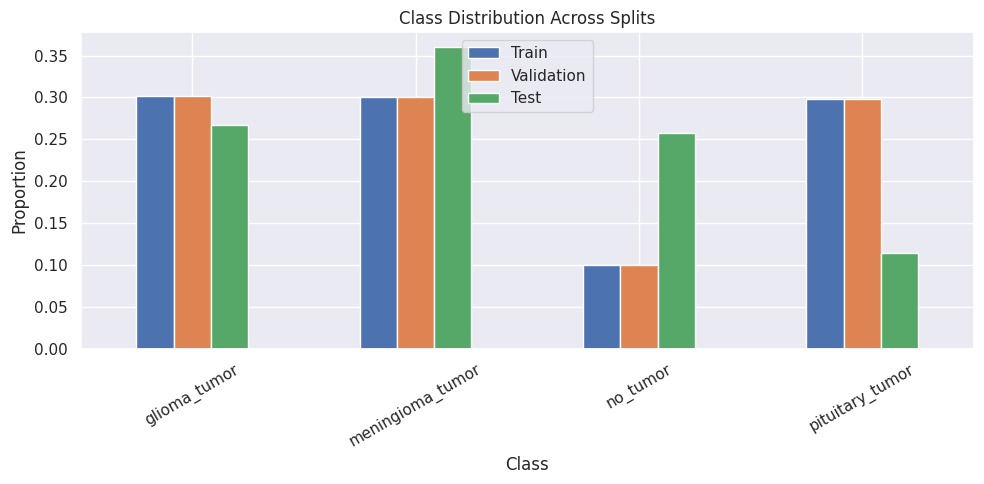

In [131]:


distribution = pd.DataFrame({
    "Train": train_split_df["label"].value_counts(
        normalize=True
    ),
    "Validation": valid_split_df["label"].value_counts(
        normalize=True
    ),
    "Test": test_df_clean["label"].value_counts(
        normalize=True
    )
}).sort_index()

print(distribution.round(4))

distribution.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Class Distribution Across Splits")
plt.ylabel("Proportion")
plt.xlabel("Class")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

In [132]:


train_hashes = set(train_split_df["file_hash"])
valid_hashes = set(valid_split_df["file_hash"])
test_hashes = set(test_df_clean["file_hash"])

train_valid_overlap = train_hashes & valid_hashes
train_test_overlap = train_hashes & test_hashes
valid_test_overlap = valid_hashes & test_hashes

print("=" * 60)
print("FINAL DATA LEAKAGE CHECK")
print("=" * 60)

print("Train ↔ Validation exact overlap:",
      len(train_valid_overlap))

print("Train ↔ Test exact overlap:",
      len(train_test_overlap))

print("Validation ↔ Test exact overlap:",
      len(valid_test_overlap))

assert len(train_valid_overlap) == 0
assert len(train_test_overlap) == 0
assert len(valid_test_overlap) == 0

print("\n✓ No exact duplicate leakage detected.")

FINAL DATA LEAKAGE CHECK
Train ↔ Validation exact overlap: 0
Train ↔ Test exact overlap: 0
Validation ↔ Test exact overlap: 0

✓ No exact duplicate leakage detected.


#Encoding

In [133]:


def encode_labels(df):
    df = df.copy()

    df["label_id"] = df["label"].map(CLASS_TO_INDEX)

    return df


train_split_df = encode_labels(train_split_df)
valid_split_df = encode_labels(valid_split_df)
test_df_clean = encode_labels(test_df_clean)

print(train_split_df.head())

print("\nLabel mapping:")
print(CLASS_TO_INDEX)

                                                path             label  \
0  /content/brain_tumor_dataset/Training/glioma_t...      glioma_tumor   
1  /content/brain_tumor_dataset/Training/meningio...  meningioma_tumor   
2  /content/brain_tumor_dataset/Training/no_tumor...          no_tumor   
3  /content/brain_tumor_dataset/Training/pituitar...   pituitary_tumor   
4  /content/brain_tumor_dataset/Training/glioma_t...      glioma_tumor   

            split                                          file_hash  label_id  
0  train_original  2dc68dec9209b4528258d3b13ac6346c91dff9c7545934...         0  
1  train_original  86c9a8bb0fcdb1bb09bed65acf42001fb7e1cada3b70dd...         1  
2  train_original  dd4ddc577d69ed2b40ac77e48195ea19bedf7fd3e7c65a...         2  
3  train_original  9dd82ba057eed76ed646f547d3a24df84f66a3ecc4f50b...         3  
4  train_original  cc72bdbe5b14b0ec86d1b240a5c02a2ad437c4ef27f946...         0  

Label mapping:
{'glioma_tumor': 0, 'meningioma_tumor': 1, 'no_tumor'

In [134]:


for name, df in [
    ("Train", train_split_df),
    ("Validation", valid_split_df),
    ("Test", test_df_clean)
]:

    print(f"\n{name}")
    print("-" * 40)

    print("Missing paths:", df["path"].isna().sum())
    print("Missing labels:", df["label"].isna().sum())
    print("Missing label IDs:", df["label_id"].isna().sum())

    print(
        "Invalid label IDs:",
        (~df["label_id"].isin(range(NUM_CLASSES))).sum()
    )

assert train_split_df["label_id"].isna().sum() == 0
assert valid_split_df["label_id"].isna().sum() == 0
assert test_df_clean["label_id"].isna().sum() == 0

print("\n✓ Label integrity verified.")


Train
----------------------------------------
Missing paths: 0
Missing labels: 0
Missing label IDs: 0
Invalid label IDs: 0

Validation
----------------------------------------
Missing paths: 0
Missing labels: 0
Missing label IDs: 0
Invalid label IDs: 0

Test
----------------------------------------
Missing paths: 0
Missing labels: 0
Missing label IDs: 0
Invalid label IDs: 0

✓ Label integrity verified.


#Visualize

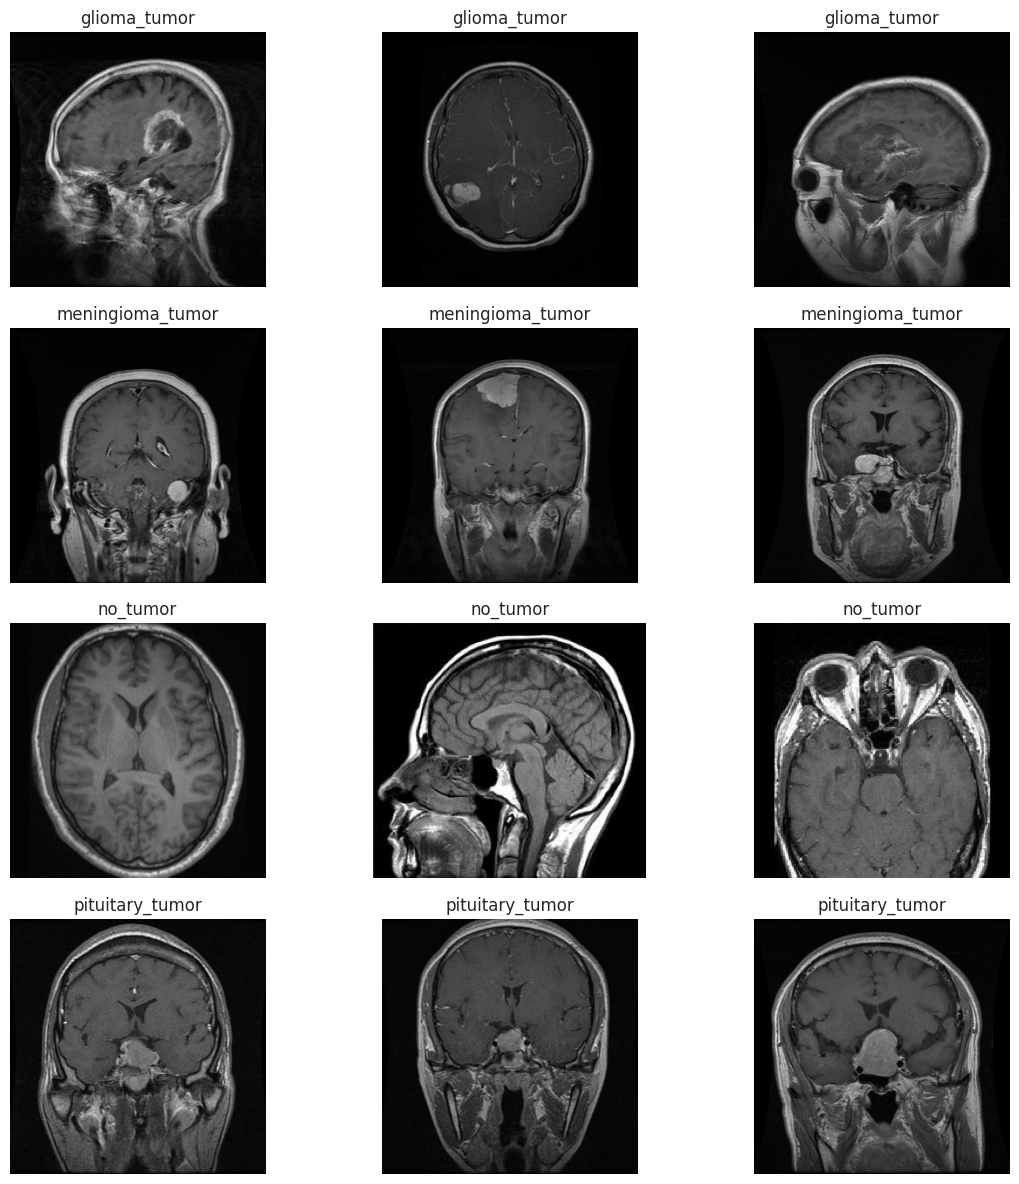

In [135]:


def show_samples(df, samples_per_class=3):

    fig, axes = plt.subplots(
        NUM_CLASSES,
        samples_per_class,
        figsize=(12, 12)
    )

    for class_idx, class_name in enumerate(CLASS_NAMES):

        class_samples = df[
            df["label"] == class_name
        ].sample(
            n=min(
                samples_per_class,
                len(df[df["label"] == class_name])
            ),
            random_state=SEED
        )

        for col_idx, (_, row) in enumerate(
            class_samples.iterrows()
        ):

            img = cv2.imread(row["path"])

            img = cv2.cvtColor(
                img,
                cv2.COLOR_BGR2RGB
            )

            axes[class_idx, col_idx].imshow(img)
            axes[class_idx, col_idx].set_title(
                class_name
            )
            axes[class_idx, col_idx].axis("off")

    plt.tight_layout()
    plt.show()


show_samples(train_split_df)

#Prepare Data Set

In [136]:


AUTOTUNE = tf.data.AUTOTUNE


def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMAGE_SIZE, IMAGE_SIZE]
    )

    image = tf.cast(
        image,
        tf.float32
    )

    return image, label


def create_dataset(df, training=False):

    paths = df["path"].values
    labels = df["label_id"].values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(
        BATCH_SIZE
    )

    dataset = dataset.prefetch(
        AUTOTUNE
    )

    return dataset

In [137]:


train_ds = create_dataset(
    train_split_df,
    training=True
)

valid_ds = create_dataset(
    valid_split_df,
    training=False
)

test_ds = create_dataset(
    test_df_clean,
    training=False
)

print("Datasets created successfully.")

Datasets created successfully.


In [138]:


images, labels = next(iter(train_ds))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print(
    "Pixel range:",
    float(tf.reduce_min(images)),
    "→",
    float(tf.reduce_max(images))
)

Images shape: (16, 256, 256, 3)
Labels shape: (16,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'int32'>
Pixel range: 0.0 → 255.0


#Visualize

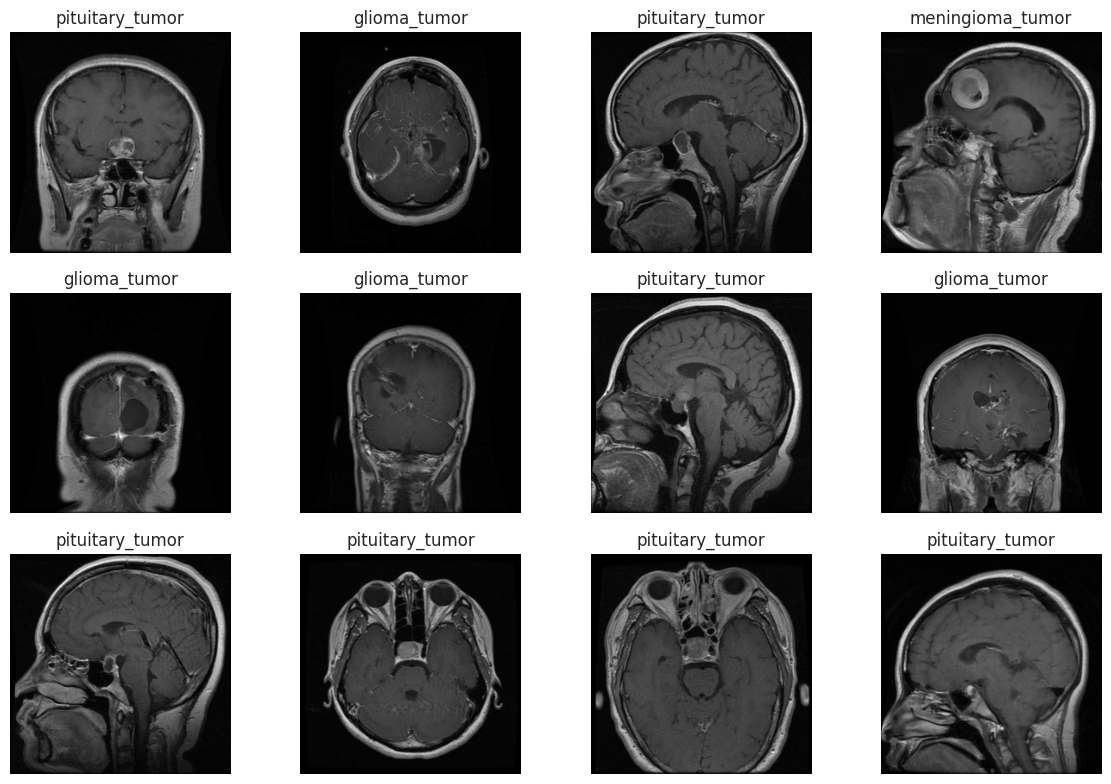

In [139]:


images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 8))

for i in range(min(12, len(images))):

    plt.subplot(3, 4, i + 1)

    plt.imshow(
        tf.cast(images[i], tf.uint8)
    )

    plt.title(
        CLASS_NAMES[int(labels[i])]
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [140]:


print("=" * 60)
print("FINAL DATASET SUMMARY")
print("=" * 60)

print(f"Train      : {len(train_split_df):,}")
print(f"Validation : {len(valid_split_df):,}")
print(f"Test       : {len(test_df_clean):,}")
print(
    f"Total      : "
    f"{len(train_split_df) + len(valid_split_df) + len(test_df_clean):,}"
)

print("\nClass mapping:")

for class_name, class_id in CLASS_TO_INDEX.items():
    print(f"{class_id} → {class_name}")

FINAL DATASET SUMMARY
Train      : 2,170
Validation : 543
Test       : 314
Total      : 3,027

Class mapping:
0 → glioma_tumor
1 → meningioma_tumor
2 → no_tumor
3 → pituitary_tumor


#EFFICENTNETB0 Transfer learning

In [141]:
from tensorflow.keras.applications import EfficientNetB0

base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
)

# Freeze the entire pretrained backbone
base_model.trainable = False

print("Number of backbone layers:", len(base_model.layers))
print(
    "Trainable backbone layers:",
    sum(layer.trainable for layer in base_model.layers)
)

Number of backbone layers: 238
Trainable backbone layers: 0


In [142]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, Model

base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
)

# Freeze backbone for Stage 1
base_model.trainable = False


inputs = tf.keras.Input(
    shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
)

x = base_model(
    inputs,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    1024,
    activation="relu"
)(x)

x = layers.Dropout(
    0.4
)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

transfer_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetB0_ReferenceHead"
)

transfer_model.summary()

Model: "EfficientNetB0_ReferenceHead"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_14 (InputLayer)     │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 8, 8, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 1024)           │     1,311,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 4)              │         4,100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,365,415 (20.47 MB)

 Trainable params: 1,315,844 (5.02 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [143]:


transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=[
        "accuracy"
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [144]:


checkpoint_stage1 = ModelCheckpoint(
    "efficientnetb0_1024_stage1_best.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stopping_stage1 = EarlyStopping(
    monitor="val_loss",
    patience=5,
    mode="min",
    restore_best_weights=True,
    verbose=1
)

reduce_lr_stage1 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    mode="min",
    verbose=1
)

callbacks_stage1 = [
    checkpoint_stage1,
    early_stopping_stage1,
    reduce_lr_stage1
]

In [145]:


EPOCHS_STAGE1 = 15

history_stage1 = transfer_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=EPOCHS_STAGE1,
    callbacks=callbacks_stage1,
    verbose=1
)

Epoch 1/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - accuracy: 0.6751 - loss: 0.8318
Epoch 1: val_accuracy improved from None to 0.79190, saving model to efficientnetb0_1024_stage1_best.keras

Epoch 1: finished saving model to efficientnetb0_1024_stage1_best.keras
136/136 ━━━━━━━━━━━━━━━━━━━━ 71s 312ms/step - accuracy: 0.7576 - loss: 0.6166 - val_accuracy: 0.7919 - val_loss: 0.5035 - learning_rate: 0.0010
Epoch 2/15
134/136 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8308 - loss: 0.4576
Epoch 2: val_accuracy improved from 0.79190 to 0.84715, saving model to efficientnetb0_1024_stage1_best.keras

Epoch 2: finished saving model to efficientnetb0_1024_stage1_best.keras
136/136 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - accuracy: 0.8396 - loss: 0.4152 - val_accuracy: 0.8471 - val_loss: 0.3834 - learning_rate: 0.0010
Epoch 3/15
134/136 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.8738 - loss: 0.3462
Epoch 3: val_accuracy improved from 0.84715 to 0.88029, saving model to efficientnetb0_10

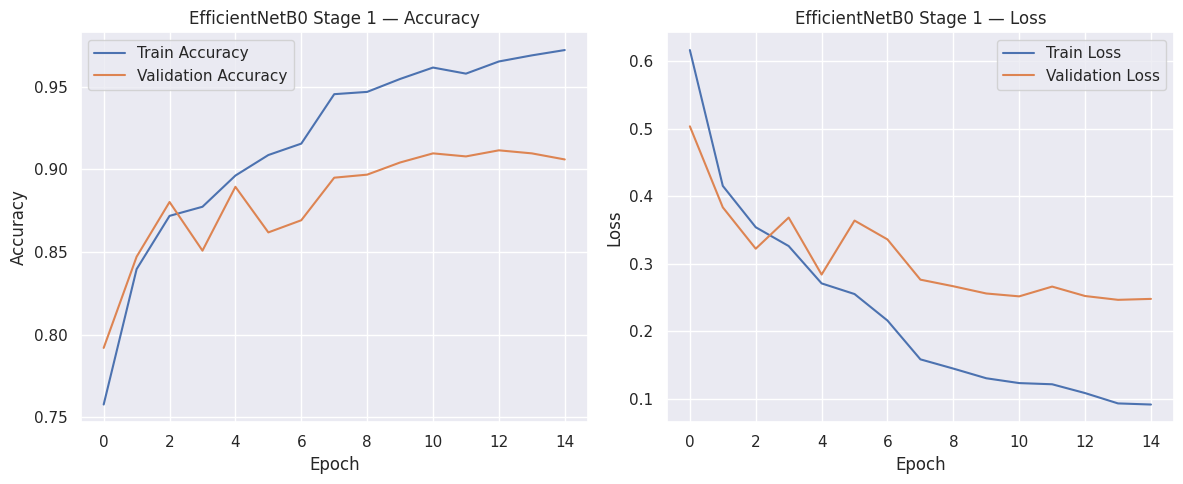

In [146]:

def plot_training_history(history, title):

    history_dict = history.history

    plt.figure(figsize=(12, 5))

    # Accuracy
    plt.subplot(1, 2, 1)

    plt.plot(
        history_dict["accuracy"],
        label="Train Accuracy"
    )

    plt.plot(
        history_dict["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.title(f"{title} — Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)

    # Loss
    plt.subplot(1, 2, 2)

    plt.plot(
        history_dict["loss"],
        label="Train Loss"
    )

    plt.plot(
        history_dict["val_loss"],
        label="Validation Loss"
    )

    plt.title(f"{title} — Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()


plot_training_history(
    history_stage1,
    "EfficientNetB0 Stage 1"
)

In [147]:
transfer_model.load_weights(
    "efficientnetb0_1024_stage1_best.keras"
)

print("Best Stage-1 weights loaded.")

Best Stage-1 weights loaded.


In [148]:
test_loss, test_accuracy = transfer_model.evaluate(
    test_ds,
    verbose=1
)

print("\n" + "=" * 60)
print("EFFICIENTNETB0 — STAGE 1 TEST RESULT")
print("=" * 60)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 289ms/step - accuracy: 0.7229 - loss: 1.5345

EFFICIENTNETB0 — STAGE 1 TEST RESULT
Test Loss     : 1.5345
Test Accuracy : 0.7229
Test Accuracy : 72.29%


In [149]:
transfer_model.load_weights(
    "efficientnetb0_1024_stage1_best.keras"
)

print("Best Stage-1 weights loaded.")

Best Stage-1 weights loaded.


In [150]:
base_model.trainable = True

# Freeze everything first
for layer in base_model.layers:
    layer.trainable = False

# Unfreeze only the last 30 layers
FINE_TUNE_LAYERS = 30

for layer in base_model.layers[-FINE_TUNE_LAYERS:]:
    layer.trainable = True

print(
    "Total backbone layers:",
    len(base_model.layers)
)

print(
    "Trainable backbone layers:",
    sum(
        layer.trainable
        for layer in base_model.layers
    )
)

print(
    "Total trainable model layers:",
    sum(
        layer.trainable
        for layer in transfer_model.layers
    )
)

Total backbone layers: 238
Trainable backbone layers: 30
Total trainable model layers: 6


In [151]:
for layer in base_model.layers[-FINE_TUNE_LAYERS:]:

    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False

trainable_backbone = [
    layer.name
    for layer in base_model.layers
    if layer.trainable
]

print(
    "Trainable backbone layers:",
    len(trainable_backbone)
)

print("\nLast trainable layers:")

for name in trainable_backbone[-15:]:
    print(name)

Trainable backbone layers: 23

Last trainable layers:
block6d_project_conv
block6d_drop
block6d_add
block7a_expand_conv
block7a_expand_activation
block7a_dwconv
block7a_activation
block7a_se_squeeze
block7a_se_reshape
block7a_se_reduce
block7a_se_expand
block7a_se_excite
block7a_project_conv
top_conv
top_activation


In [152]:
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=[
        "accuracy"
    ]
)

print("Fine-tuning model compiled.")

Fine-tuning model compiled.


In [153]:
checkpoint_stage2 = ModelCheckpoint(
    "efficientnetb0_finetuned_best.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stopping_stage2 = EarlyStopping(
    monitor="val_loss",
    patience=6,
    mode="min",
    restore_best_weights=True,
    verbose=1
)

reduce_lr_stage2 = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    mode="min",
    verbose=1
)

callbacks_stage2 = [
    checkpoint_stage2,
    early_stopping_stage2,
    reduce_lr_stage2
]

In [154]:
EPOCHS_STAGE2 = 15

history_stage2 = transfer_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=EPOCHS_STAGE2,
    callbacks=callbacks_stage2,
    verbose=1
)

Epoch 1/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.9676 - loss: 0.0950
Epoch 1: val_accuracy improved from None to 0.90792, saving model to efficientnetb0_finetuned_best.keras

Epoch 1: finished saving model to efficientnetb0_finetuned_best.keras
136/136 ━━━━━━━━━━━━━━━━━━━━ 58s 235ms/step - accuracy: 0.9677 - loss: 0.0954 - val_accuracy: 0.9079 - val_loss: 0.2447 - learning_rate: 1.0000e-05
Epoch 2/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9635 - loss: 0.0975
Epoch 2: val_accuracy did not improve from 0.90792
136/136 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.9710 - loss: 0.0871 - val_accuracy: 0.9024 - val_loss: 0.2535 - learning_rate: 1.0000e-05
Epoch 3/15
136/136 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9647 - loss: 0.0973
Epoch 3: val_accuracy improved from 0.90792 to 0.91529, saving model to efficientnetb0_finetuned_best.keras

Epoch 3: finished saving model to efficientnetb0_finetuned_best.keras

Epoch 3: ReduceLROnPlateau reducing l

In [155]:
transfer_model.load_weights(
    "efficientnetb0_finetuned_best.keras"
)

print("Best fine-tuned weights loaded.")

Best fine-tuned weights loaded.


In [156]:
test_loss_stage2, test_accuracy_stage2 = transfer_model.evaluate(
    test_ds,
    verbose=1
)

print("\n" + "=" * 60)
print("EFFICIENTNETB0 — STAGE 2 TEST RESULT")
print("=" * 60)

print(f"Test Loss     : {test_loss_stage2:.4f}")
print(f"Test Accuracy : {test_accuracy_stage2:.4f}")
print(f"Test Accuracy : {test_accuracy_stage2 * 100:.2f}%")

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 271ms/step - accuracy: 0.7261 - loss: 1.6042

EFFICIENTNETB0 — STAGE 2 TEST RESULT
Test Loss     : 1.6042
Test Accuracy : 0.7261
Test Accuracy : 72.61%


In [118]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

y_true_stage2 = []
y_pred_stage2 = []

for images, labels_batch in test_ds:

    predictions = transfer_model.predict(
        images,
        verbose=0
    )

    y_true_stage2.extend(
        labels_batch.numpy()
    )

    y_pred_stage2.extend(
        np.argmax(predictions, axis=1)
    )

y_true_stage2 = np.array(y_true_stage2)
y_pred_stage2 = np.array(y_pred_stage2)

print(
    classification_report(
        y_true_stage2,
        y_pred_stage2,
        target_names=CLASS_NAMES,
        digits=4
    )
)

                  precision    recall  f1-score   support

    glioma_tumor     0.8000    0.2857    0.4211        84
meningioma_tumor     0.6604    0.9292    0.7721       113
        no_tumor     0.7634    0.8765    0.8161        81
 pituitary_tumor     0.9062    0.8056    0.8529        36

        accuracy                         0.7293       314
       macro avg     0.7825    0.7243    0.7155       314
    weighted avg     0.7525    0.7293    0.6988       314



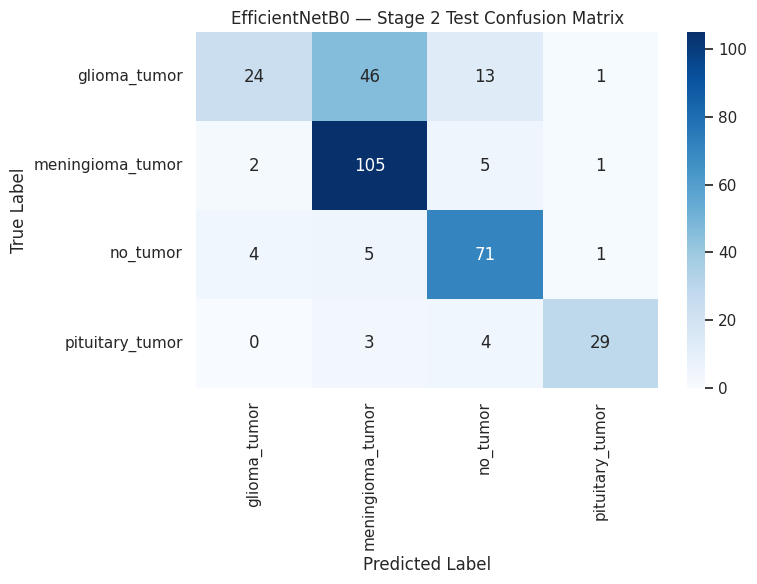

In [119]:
cm_stage2 = confusion_matrix(
    y_true_stage2,
    y_pred_stage2
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_stage2,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title(
    "EfficientNetB0 — Stage 2 Test Confusion Matrix"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

#Error analysis

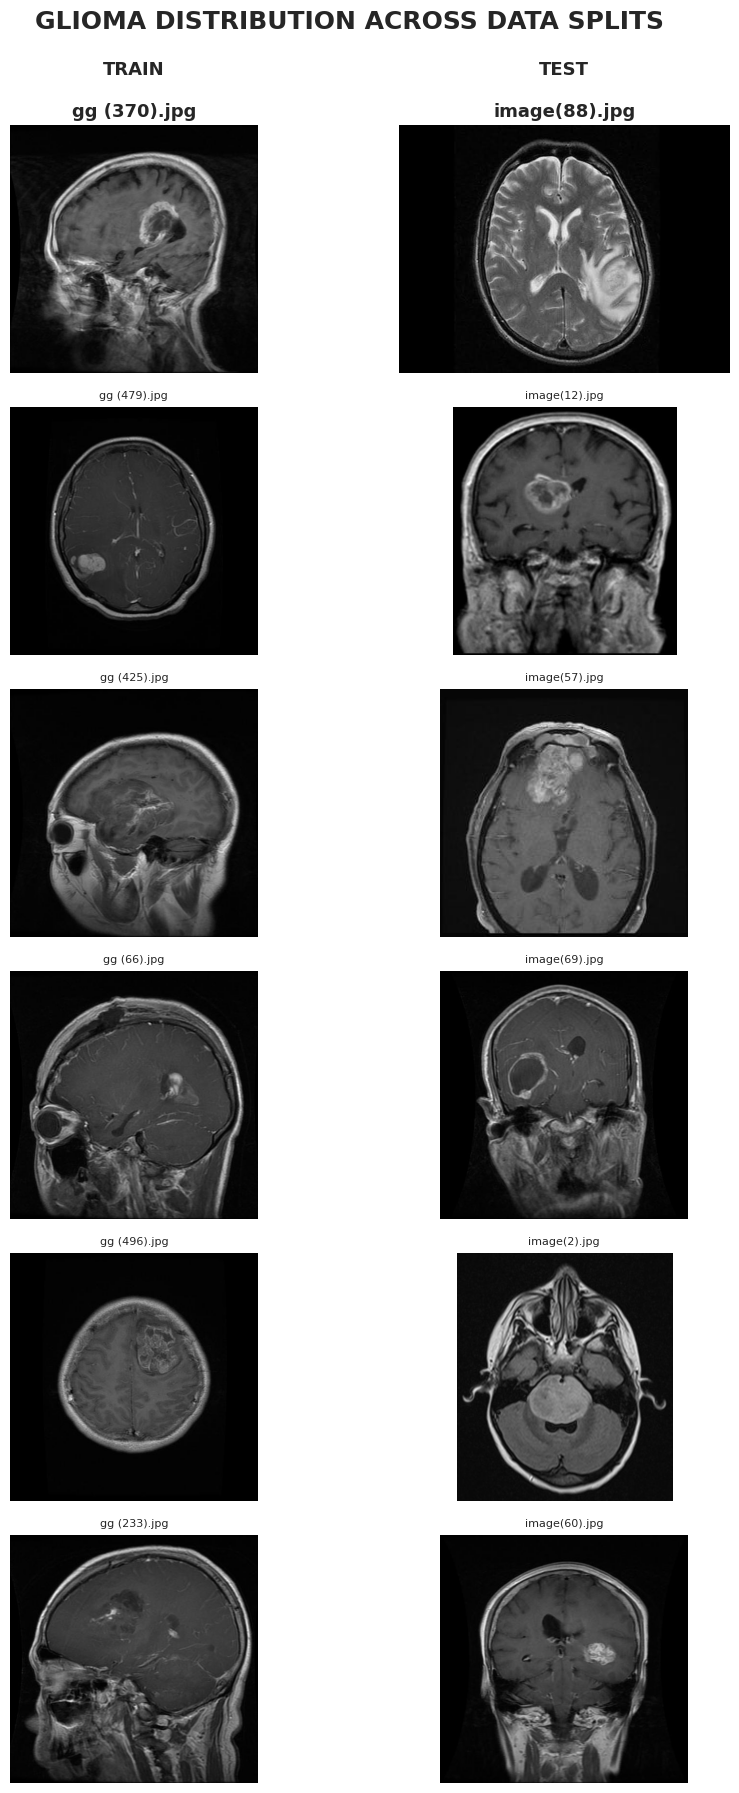

In [65]:
N_SAMPLES = 6

fig, axes = plt.subplots(
    N_SAMPLES,
    2,
    figsize=(10, 18)
)

split_data = [
    ("TRAIN", glioma_train),
    ("TEST", glioma_test)
]

for col, (split_name, df) in enumerate(split_data):

    samples = df.sample(
        n=N_SAMPLES,
        random_state=SEED
    )

    for row, (_, sample) in enumerate(
        samples.iterrows()
    ):

        img = cv2.imread(sample["path"])

        img = cv2.cvtColor(
            img,
            cv2.COLOR_BGR2RGB
        )

        axes[row, col].imshow(img)
        axes[row, col].axis("off")

        # Filename
        axes[row, col].set_title(
            Path(sample["path"]).name,
            fontsize=8
        )

        # Strong column label
        if row == 0:
            axes[row, col].set_title(
                f"{split_name}\n\n"
                f"{Path(sample['path']).name}",
                fontsize=13,
                fontweight="bold"
            )


plt.suptitle(
    "GLIOMA DISTRIBUTION ACROSS DATA SPLITS",
    fontsize=18,
    fontweight="bold",
    y=0.995
)

plt.tight_layout()
plt.show()

#BUILD CNN

In [157]:
CNN_IMAGE_SIZE = 256
CNN_BATCH_SIZE = 32
CNN_NUM_CLASSES = 4

print("CNN image size :", CNN_IMAGE_SIZE)
print("CNN batch size :", CNN_BATCH_SIZE)

CNN image size : 256
CNN batch size : 32


In [158]:

def load_cnn_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [CNN_IMAGE_SIZE, CNN_IMAGE_SIZE]
    )

    image = tf.cast(
        image,
        tf.float32
    )

    # Reference CNN used normalized images
    image = image / 255.0

    return image, label

In [159]:

AUTOTUNE = tf.data.AUTOTUNE


def create_cnn_dataset(df, training=False):

    paths = df["path"].values

    labels = df["label_id"].values.astype(
        np.int32
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:

        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_cnn_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(
        CNN_BATCH_SIZE
    )

    dataset = dataset.prefetch(
        AUTOTUNE
    )

    return dataset


cnn_train_ds = create_cnn_dataset(
    train_split_df,
    training=True
)

cnn_valid_ds = create_cnn_dataset(
    valid_split_df,
    training=False
)

cnn_test_ds = create_cnn_dataset(
    test_df_clean,
    training=False
)

print("CNN datasets created successfully.")

CNN datasets created successfully.


In [160]:

images, labels = next(iter(cnn_train_ds))

print("Images shape :", images.shape)
print("Labels shape :", labels.shape)
print("Image dtype  :", images.dtype)

print(
    "Pixel range  :",
    float(tf.reduce_min(images)),
    "→",
    float(tf.reduce_max(images))
)

Images shape : (32, 256, 256, 3)
Labels shape : (32,)
Image dtype  : <dtype: 'float32'>
Pixel range  : 0.0 → 1.0


In [161]:


from tensorflow.keras import layers, Model

cnn_inputs = tf.keras.Input(
    shape=(
        CNN_IMAGE_SIZE,
        CNN_IMAGE_SIZE,
        3
    )
)

x = layers.Conv2D(
    32,
    kernel_size=(5, 5),
    activation="relu",
    padding="same"
)(cnn_inputs)

x = layers.MaxPooling2D()(x)

x = layers.Dropout(0.15)(x)


x = layers.Conv2D(
    32,
    kernel_size=(5, 5),
    activation="relu",
    padding="same"
)(x)

x = layers.MaxPooling2D()(x)

x = layers.Dropout(0.15)(x)


x = layers.Conv2D(
    32,
    kernel_size=(3, 3),
    activation="relu",
    padding="same"
)(x)

x = layers.MaxPooling2D()(x)

x = layers.Dropout(0.15)(x)


x = layers.Conv2D(
    64,
    kernel_size=(2, 2),
    activation="relu",
    padding="same"
)(x)

x = layers.MaxPooling2D()(x)

x = layers.Dropout(0.15)(x)


x = layers.Flatten()(x)

x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(0.45)(x)

cnn_outputs = layers.Dense(
    CNN_NUM_CLASSES,
    activation="softmax"
)(x)


cnn_model = Model(
    inputs=cnn_inputs,
    outputs=cnn_outputs,
    name="Custom_CNN_Reference"
)

cnn_model.summary()

Model: "Custom_CNN_Reference"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_15 (InputLayer)     │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,143,364 (8.18 MB)

 Trainable params: 2,143,364 (8.18 MB)

 Non-trainable params: 0 (0.00 B)

In [162]:


cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN compiled successfully.")

CNN compiled successfully.


In [163]:


cnn_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "custom_cnn_reference_best.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

cnn_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    mode="min",
    restore_best_weights=True,
    verbose=1
)

cnn_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    min_lr=1e-7,
    mode="min",
    verbose=1
)

cnn_callbacks = [
    cnn_checkpoint,
    cnn_early_stopping,
    cnn_reduce_lr
]

In [164]:
CNN_EPOCHS = 45

cnn_history = cnn_model.fit(
    cnn_train_ds,
    validation_data=cnn_valid_ds,
    epochs=CNN_EPOCHS,
    callbacks=cnn_callbacks,
    verbose=1
)

Epoch 1/45
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 260ms/step - accuracy: 0.4535 - loss: 1.2741
Epoch 1: val_accuracy improved from None to 0.58379, saving model to custom_cnn_reference_best.keras

Epoch 1: finished saving model to custom_cnn_reference_best.keras
68/68 ━━━━━━━━━━━━━━━━━━━━ 42s 334ms/step - accuracy: 0.5092 - loss: 1.1526 - val_accuracy: 0.5838 - val_loss: 0.9346 - learning_rate: 0.0010
Epoch 2/45
67/68 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.6123 - loss: 0.9041
Epoch 2: val_accuracy improved from 0.58379 to 0.64088, saving model to custom_cnn_reference_best.keras

Epoch 2: finished saving model to custom_cnn_reference_best.keras
68/68 ━━━━━━━━━━━━━━━━━━━━ 8s 72ms/step - accuracy: 0.6373 - loss: 0.8542 - val_accuracy: 0.6409 - val_loss: 0.7714 - learning_rate: 0.0010
Epoch 3/45
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.7317 - loss: 0.6492
Epoch 3: val_accuracy improved from 0.64088 to 0.72376, saving model to custom_cnn_reference_best.keras

Epoch 3: finished 

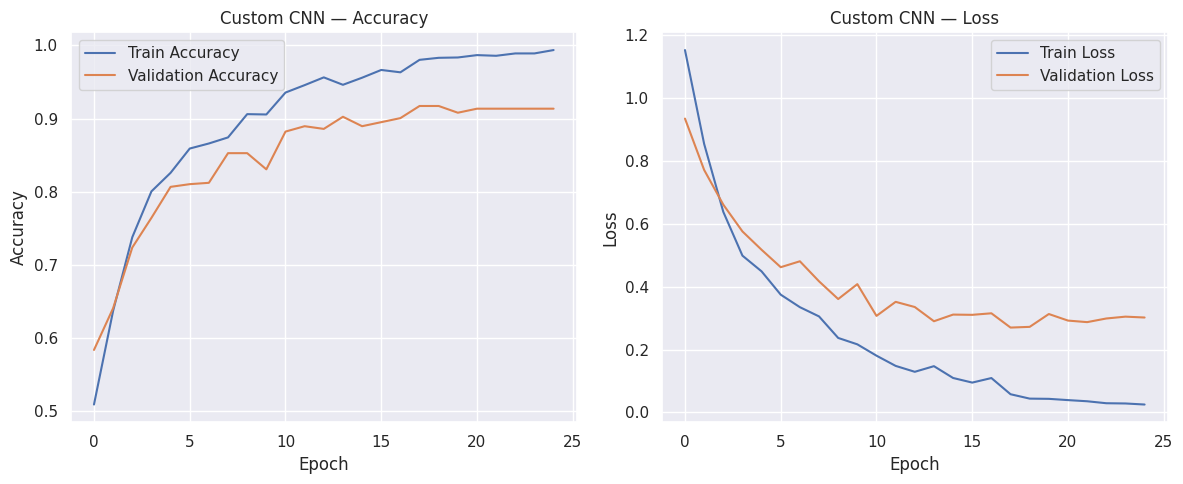

In [165]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    cnn_history.history["accuracy"],
    label="Train Accuracy"
)

plt.plot(
    cnn_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Custom CNN — Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)


plt.subplot(1, 2, 2)

plt.plot(
    cnn_history.history["loss"],
    label="Train Loss"
)

plt.plot(
    cnn_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Custom CNN — Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [166]:
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    cnn_test_ds,
    verbose=1
)

print("\n" + "=" * 60)
print("CUSTOM CNN — TEST RESULT")
print("=" * 60)

print(f"Test Loss     : {cnn_test_loss:.4f}")
print(f"Test Accuracy : {cnn_test_accuracy:.4f}")
print(f"Test Accuracy : {cnn_test_accuracy * 100:.2f}%")

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 193ms/step - accuracy: 0.6465 - loss: 4.0870

CUSTOM CNN — TEST RESULT
Test Loss     : 4.0870
Test Accuracy : 0.6465
Test Accuracy : 64.65%


In [167]:
cnn_y_true = []
cnn_y_pred = []

for images, labels_batch in cnn_test_ds:

    predictions = cnn_model.predict(
        images,
        verbose=0
    )

    cnn_y_true.extend(
        labels_batch.numpy()
    )

    cnn_y_pred.extend(
        np.argmax(predictions, axis=1)
    )


cnn_y_true = np.array(cnn_y_true)
cnn_y_pred = np.array(cnn_y_pred)


print(
    classification_report(
        cnn_y_true,
        cnn_y_pred,
        target_names=CLASS_NAMES,
        digits=4
    )
)

                  precision    recall  f1-score   support

    glioma_tumor     0.7826    0.2143    0.3364        84
meningioma_tumor     0.6352    0.8938    0.7426       113
        no_tumor     0.5842    0.7284    0.6484        81
 pituitary_tumor     0.8065    0.6944    0.7463        36

        accuracy                         0.6465       314
       macro avg     0.7021    0.6327    0.6184       314
    weighted avg     0.6811    0.6465    0.6101       314



#Mobile Net

In [170]:
MOBILE_IMAGE_SIZE = 224
MOBILE_BATCH_SIZE = 32
MOBILE_NUM_CLASSES = NUM_CLASSES

print("MobileNetV2 image size :", MOBILE_IMAGE_SIZE)
print("MobileNetV2 batch size :", MOBILE_BATCH_SIZE)
print("Number of classes     :", MOBILE_NUM_CLASSES)

MobileNetV2 image size : 224
MobileNetV2 batch size : 32
Number of classes     : 4


In [171]:
def load_mobile_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [MOBILE_IMAGE_SIZE, MOBILE_IMAGE_SIZE]
    )

    image = tf.keras.applications.mobilenet_v2.preprocess_input(
        image
    )

    return image, label

In [172]:
AUTOTUNE = tf.data.AUTOTUNE


def create_mobile_dataset(df, training=False):

    paths = df["path"].values

    labels = df["label_id"].values.astype(
        np.int32
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:

        dataset = dataset.shuffle(
            buffer_size=1000,
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_mobile_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(
        MOBILE_BATCH_SIZE
    )

    dataset = dataset.prefetch(
        AUTOTUNE
    )

    return dataset


mobile_train_ds = create_mobile_dataset(
    train_split_df,
    training=True
)

mobile_valid_ds = create_mobile_dataset(
    valid_split_df,
    training=False
)

mobile_test_ds = create_mobile_dataset(
    test_df_clean,
    training=False
)

print("MobileNetV2 datasets created successfully.")

MobileNetV2 datasets created successfully.


In [173]:
images, labels = next(iter(mobile_train_ds))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print(
    "Pixel range:",
    float(tf.reduce_min(images)),
    "→",
    float(tf.reduce_max(images))
)

Images shape: (32, 224, 224, 3)
Labels shape: (32,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'int32'>
Pixel range: -1.0 → 0.9955042600631714


In [174]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, Model

mobile_base = MobileNetV2(
    input_shape=(
        MOBILE_IMAGE_SIZE,
        MOBILE_IMAGE_SIZE,
        3
    ),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained backbone
mobile_base.trainable = False

print(
    "Total backbone layers:",
    len(mobile_base.layers)
)

print(
    "Trainable backbone layers:",
    sum(
        layer.trainable
        for layer in mobile_base.layers
    )
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total backbone layers: 154
Trainable backbone layers: 0


In [175]:
mobile_inputs = tf.keras.Input(
    shape=(
        MOBILE_IMAGE_SIZE,
        MOBILE_IMAGE_SIZE,
        3
    )
)

x = mobile_base(
    mobile_inputs,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(
    0.3
)(x)

mobile_outputs = layers.Dense(
    MOBILE_NUM_CLASSES,
    activation="softmax"
)(x)

mobile_model = Model(
    inputs=mobile_inputs,
    outputs=mobile_outputs,
    name="MobileNetV2_BrainTumor"
)

mobile_model.summary()

Model: "MobileNetV2_BrainTumor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_17 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [176]:
mobile_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("MobileNetV2 compiled successfully.")

MobileNetV2 compiled successfully.


In [177]:
mobile_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

mobile_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

mobile_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "mobilenetv2_stage1_best.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

mobile_callbacks = [
    mobile_early_stopping,
    mobile_reduce_lr,
    mobile_checkpoint
]

In [178]:
MOBILE_EPOCHS = 15

mobile_history = mobile_model.fit(
    mobile_train_ds,
    validation_data=mobile_valid_ds,
    epochs=MOBILE_EPOCHS,
    callbacks=mobile_callbacks,
    verbose=1
)

Epoch 1/15
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - accuracy: 0.5864 - loss: 0.9445
Epoch 1: val_accuracy improved from None to 0.82320, saving model to mobilenetv2_stage1_best.keras

Epoch 1: finished saving model to mobilenetv2_stage1_best.keras
68/68 ━━━━━━━━━━━━━━━━━━━━ 45s 420ms/step - accuracy: 0.7065 - loss: 0.6992 - val_accuracy: 0.8232 - val_loss: 0.4436 - learning_rate: 0.0010
Epoch 2/15
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.8482 - loss: 0.3744
Epoch 2: val_accuracy improved from 0.82320 to 0.86372, saving model to mobilenetv2_stage1_best.keras

Epoch 2: finished saving model to mobilenetv2_stage1_best.keras
68/68 ━━━━━━━━━━━━━━━━━━━━ 6s 83ms/step - accuracy: 0.8539 - loss: 0.3762 - val_accuracy: 0.8637 - val_loss: 0.3979 - learning_rate: 0.0010
Epoch 3/15
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.8729 - loss: 0.3059
Epoch 3: val_accuracy did not improve from 0.86372
68/68 ━━━━━━━━━━━━━━━━━━━━ 4s 65ms/step - accuracy: 0.8760 - loss: 0.3122 - val_

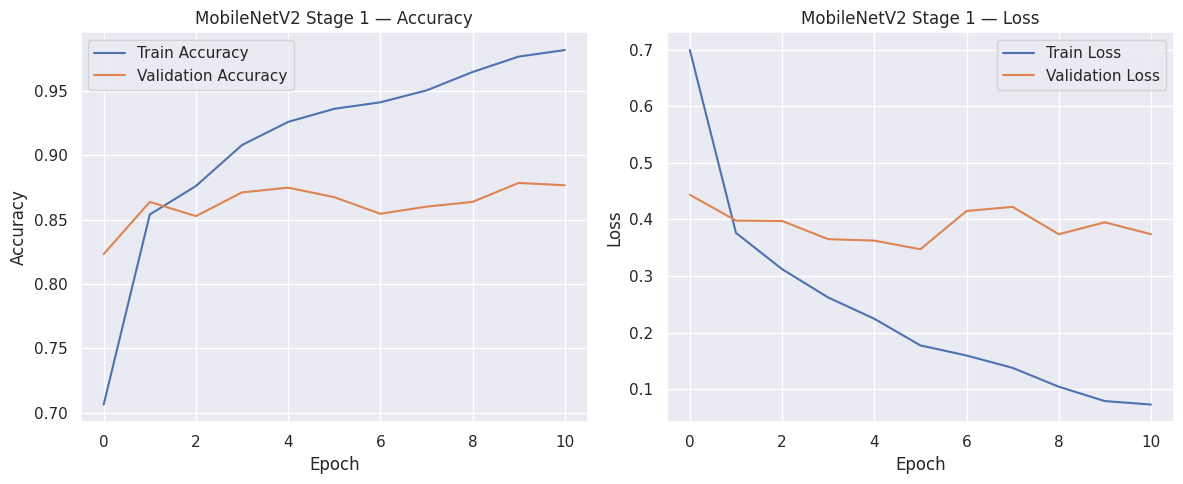

In [179]:
plot_training_history(
    mobile_history,
    "MobileNetV2 Stage 1"
)

In [180]:
# ============================================================
# MOBILENETV2 — LOAD BEST STAGE 1
# ============================================================

mobile_model.load_weights(
    "mobilenetv2_stage1_best.keras"
)

print("Best MobileNetV2 Stage-1 weights loaded.")

Best MobileNetV2 Stage-1 weights loaded.


In [181]:
mobile_test_loss, mobile_test_accuracy = mobile_model.evaluate(
    mobile_test_ds,
    verbose=1
)

print("\n" + "=" * 60)
print("MOBILENETV2 — STAGE 1 TEST RESULT")
print("=" * 60)

print(f"Test Loss     : {mobile_test_loss:.4f}")
print(f"Test Accuracy : {mobile_test_accuracy:.4f}")
print(f"Test Accuracy : {mobile_test_accuracy * 100:.2f}%")

10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 740ms/step - accuracy: 0.7006 - loss: 1.7877

MOBILENETV2 — STAGE 1 TEST RESULT
Test Loss     : 1.7877
Test Accuracy : 0.7006
Test Accuracy : 70.06%


In [182]:
mobile_y_true = []
mobile_y_pred = []

for images, labels_batch in mobile_test_ds:

    predictions = mobile_model.predict(
        images,
        verbose=0
    )

    mobile_y_true.extend(
        labels_batch.numpy()
    )

    mobile_y_pred.extend(
        np.argmax(predictions, axis=1)
    )


mobile_y_true = np.array(mobile_y_true)
mobile_y_pred = np.array(mobile_y_pred)


print(
    classification_report(
        mobile_y_true,
        mobile_y_pred,
        target_names=CLASS_NAMES,
        digits=4
    )
)

                  precision    recall  f1-score   support

    glioma_tumor     0.9048    0.2262    0.3619        84
meningioma_tumor     0.6387    0.8761    0.7388       113
        no_tumor     0.7188    0.8519    0.7797        81
 pituitary_tumor     0.7857    0.9167    0.8462        36

        accuracy                         0.7006       314
       macro avg     0.7620    0.7177    0.6816       314
    weighted avg     0.7474    0.7006    0.6608       314



#shuffling train test split

In [183]:
merged_df = pd.concat(
    [
        train_df_clean,
        test_df_clean
    ],
    ignore_index=True
)

print("=" * 60)
print("MERGED DATASET")
print("=" * 60)

print("Total images:", len(merged_df))

print("\nClass distribution:")
print(
    merged_df["label"]
    .value_counts()
    .sort_index()
)

MERGED DATASET
Total images: 3027

Class distribution:
label
glioma_tumor        902
meningioma_tumor    927
no_tumor            352
pituitary_tumor     846
Name: count, dtype: int64


In [184]:
merged_df = merged_df.sample(
    frac=1,
    random_state=101
).reset_index(drop=True)

print("Merged dataset shuffled successfully.")

Merged dataset shuffled successfully.


In [185]:
merged_train_df, merged_test_df = train_test_split(
    merged_df,
    test_size=0.10,
    random_state=101
)

merged_train_df = merged_train_df.reset_index(drop=True)
merged_test_df = merged_test_df.reset_index(drop=True)

print("=" * 60)
print("NEW TRAIN / TEST SPLIT")
print("=" * 60)

print("Train:", len(merged_train_df))
print("Test :", len(merged_test_df))

print("\nTrain distribution:")
print(
    merged_train_df["label"]
    .value_counts()
    .sort_index()
)

print("\nTest distribution:")
print(
    merged_test_df["label"]
    .value_counts()
    .sort_index()
)

NEW TRAIN / TEST SPLIT
Train: 2724
Test : 303

Train distribution:
label
glioma_tumor        811
meningioma_tumor    834
no_tumor            316
pituitary_tumor     763
Name: count, dtype: int64

Test distribution:
label
glioma_tumor        91
meningioma_tumor    93
no_tumor            36
pituitary_tumor     83
Name: count, dtype: int64


In [186]:
merged_train_df = encode_labels(
    merged_train_df
)

merged_test_df = encode_labels(
    merged_test_df
)

print("Labels encoded successfully.")

Labels encoded successfully.


In [187]:
merged_train_ds = create_dataset(
    merged_train_df,
    training=True
)

merged_test_ds = create_dataset(
    merged_test_df,
    training=False
)

print("Merged experiment datasets created.")

Merged experiment datasets created.


In [188]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, Model

merged_base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
)

merged_base_model.trainable = False


merged_inputs = tf.keras.Input(
    shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
)

x = merged_base_model(
    merged_inputs,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    1024,
    activation="relu"
)(x)

x = layers.Dropout(
    0.4
)(x)

merged_outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

merged_model = Model(
    inputs=merged_inputs,
    outputs=merged_outputs,
    name="EfficientNetB0_MergedExperiment"
)

merged_model.summary()

Model: "EfficientNetB0_MergedExperiment"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_19 (InputLayer)     │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 8, 8, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_7      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 1024)           │     1,311,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 4)              │         4,100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,365,415 (20.47 MB)

 Trainable params: 1,315,844 (5.02 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [189]:
merged_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Merged experiment model compiled.")

Merged experiment model compiled.


In [190]:
merged_checkpoint = ModelCheckpoint(
    "efficientnetb0_merged_best.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

merged_reduce_lr = ReduceLROnPlateau(
    monitor="val_accuracy",
    factor=0.1,
    patience=2,
    min_delta=0.0001,
    verbose=1
)

merged_callbacks = [
    merged_checkpoint,
    merged_reduce_lr
]

In [191]:
merged_train_final_df, merged_valid_df = train_test_split(
    merged_train_df,
    test_size=0.10,
    random_state=101
)

merged_train_final_df = (
    merged_train_final_df
    .reset_index(drop=True)
)

merged_valid_df = (
    merged_valid_df
    .reset_index(drop=True)
)

print("=" * 60)
print("MERGED EXPERIMENT — FINAL SPLITS")
print("=" * 60)

print("Train      :", len(merged_train_final_df))
print("Validation :", len(merged_valid_df))
print("Test       :", len(merged_test_df))

MERGED EXPERIMENT — FINAL SPLITS
Train      : 2451
Validation : 273
Test       : 303


In [192]:
merged_train_final_ds = create_dataset(
    merged_train_final_df,
    training=True
)

merged_valid_ds = create_dataset(
    merged_valid_df,
    training=False
)

merged_test_ds = create_dataset(
    merged_test_df,
    training=False
)

print("Final merged datasets ready.")

Final merged datasets ready.


In [193]:
merged_history = merged_model.fit(
    merged_train_final_ds,
    validation_data=merged_valid_ds,
    epochs=15,
    callbacks=merged_callbacks,
    verbose=1
)

Epoch 1/15
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.6346 - loss: 0.8498
Epoch 1: val_accuracy improved from None to 0.80952, saving model to efficientnetb0_merged_best.keras

Epoch 1: finished saving model to efficientnetb0_merged_best.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 67s 258ms/step - accuracy: 0.7189 - loss: 0.6810 - val_accuracy: 0.8095 - val_loss: 0.4627 - learning_rate: 0.0010
Epoch 2/15
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8205 - loss: 0.4585
Epoch 2: val_accuracy improved from 0.80952 to 0.82418, saving model to efficientnetb0_merged_best.keras

Epoch 2: finished saving model to efficientnetb0_merged_best.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 7s 44ms/step - accuracy: 0.8254 - loss: 0.4525 - val_accuracy: 0.8242 - val_loss: 0.4411 - learning_rate: 0.0010
Epoch 3/15
152/154 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.8136 - loss: 0.4649
Epoch 3: val_accuracy improved from 0.82418 to 0.89377, saving model to efficientnetb0_merged_best.keras

Epo

In [194]:
merged_model.load_weights(
    "efficientnetb0_merged_best.keras"
)

merged_test_loss, merged_test_accuracy = (
    merged_model.evaluate(
        merged_test_ds,
        verbose=1
    )
)

print("\n" + "=" * 60)
print("EFFICIENTNETB0 — MERGED TRAIN+TEST EXPERIMENT")
print("=" * 60)

print(f"Test Loss     : {merged_test_loss:.4f}")
print(f"Test Accuracy : {merged_test_accuracy:.4f}")
print(f"Test Accuracy : {merged_test_accuracy * 100:.2f}%")

19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 328ms/step - accuracy: 0.9076 - loss: 0.3127

EFFICIENTNETB0 — MERGED TRAIN+TEST EXPERIMENT
Test Loss     : 0.3127
Test Accuracy : 0.9076
Test Accuracy : 90.76%
